1/clkgen_freq=125.0 ns phase_shift_steps=4200
ext_offset=2 (250 ns)  offset=1000 (29.8 ns)  width=1500 (44.6 ns)  repeat=1  output=glitch_only  (pulse 44.6 ns)


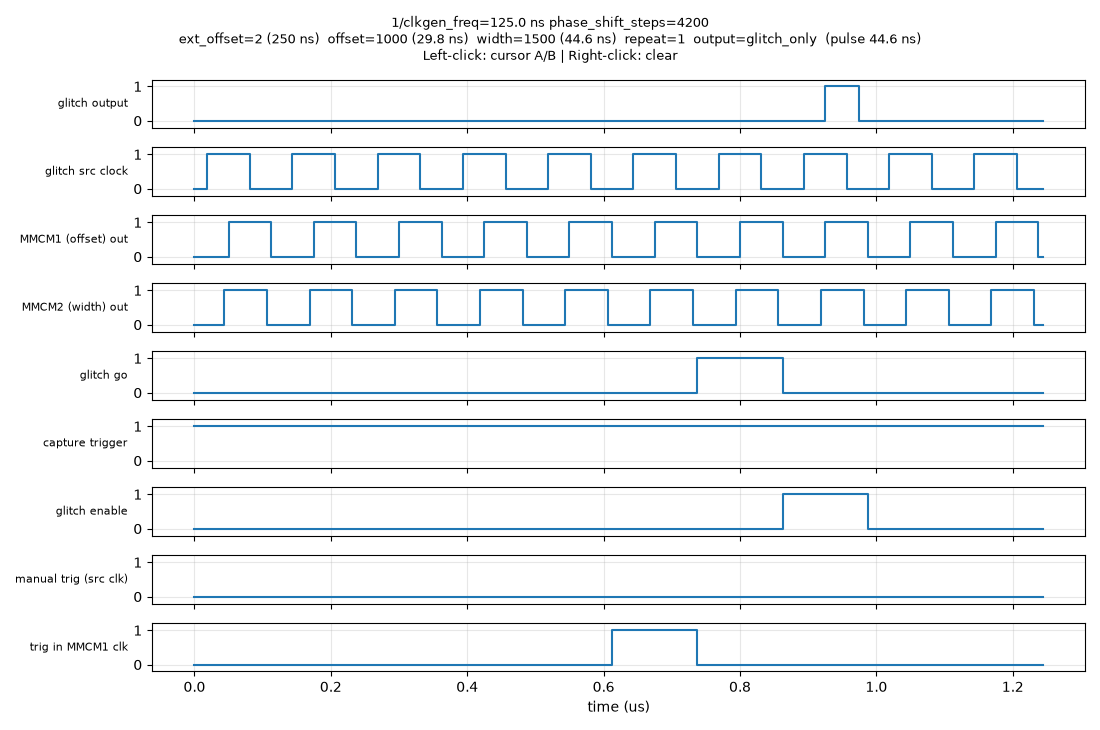

scope.glitch.clk_src  pll
scope.clock.clkgen_freq  8000000.0
scope.clock.fpga_vco_freq  600000000.0
scope.LA.sampling_clock_frequency  160002502.44140625
scope.LA.downsample  1
scope.glitch.phase_shift_steps  4200


In [14]:
%run "./LibLogicAnalyserGlitchTools.ipynb"

def pin_set(setting):
    scope.io.tio4 = setting

def pre_arm_action(scope):
    pin_set("gpio_low")

def post_arm_trigger_action(scope):
    pin_set("gpio_high")                   # rising edge on the trigger pin

def post_capture_action(scope):
    pin_set("gpio_low")

def capture_with_la(group):
    scope.errors.clear()
        
    scope.LA.capture_group = group
    scope.io.glitch_trig_mcx = 'glitch' # Glitch pulse on the Trigger/Glitch Out MCX connector
    scope.io.hs2 = 'glitch'  # Glitch on HS2, for example to feed an external device
    
    pre_arm_action(scope)
    time.sleep(0.01)
    scope.LA.arm()                        
    post_arm_trigger_action(scope)
    time.sleep(0.003)
    post_capture_action(scope)
    
    raw = scope.LA.read_capture_data()
    sigs = {}
    for i in range(9):
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break

    scope.LA.enabled = False
    return sigs



def run_glitch(scope, ext_offset=1, repeat=1, offset=0, width=1000,
               output="enable_only", oversampling=20, extra_us=2.0,
               trig_pin="tio4", fixed_latency_us=0.6, 
               trigger_src="ext_single", capture_group="glitch"):
    """Configure the glitch module, fire one glitch, capture it with the LA.

    f_glitch         : glitch clock in Hz (must match clkgen_freq / PLL setup)
    fixed_latency_us : margin for the fixed trigger->output latency
                       (about 0.43 us measured on your setup, plus some slack)
    Returns a dict with the LA data, computed times and measured timing.
    
    """
    f_glitch = scope.clock.clkgen_freq
    
    # ---- glitch module ----
    g = scope.glitch
    g.enabled = True
    g.clk_src = "pll"
    g.trigger_src = trigger_src
    g.num_glitches = 1
    g.output = output
    g.ext_offset = ext_offset
    g.repeat = repeat
    g.offset = offset
    g.width = width

    # ---- logic analyzer ----
    la = scope.LA
    la.enabled = True
    la.clk_source = "pll"
    la.capture_group = capture_group
    la.trigger_source = "trigger_glitch"   # the event ext_offset is counted from
    la.oversampling_factor = oversampling
    la.downsample = 1
    la.capture_depth = 200

    f_la = la.sampling_clock_frequency / la.downsample
    T = 1 / f_glitch
    #window = (ext_offset + repeat) * T + (extra_us + fixed_latency_us) * 1e-6
    #la.capture_depth = int(window * f_la)

    # ---- fire one glitch ----
    pin_set = lambda v: setattr(scope.io, trig_pin, v)
    pre_arm_action(scope)
    time.sleep(0.01)
    la.arm()
    scope.arm()
    post_arm_trigger_action(scope)
    res = read_capture_data(scope)
    post_capture_action(scope)

    return res

    

import chipwhisperer as cw

try:
    scope.dis()
except:
    pass
try:
    fig.dis()
except:
    pass
try:
    fig1.dis()
except:
    pass

scope = cw.scope()
scope.default_setup(verbose=False)
scope.clock.clkgen_freq = 8e6

scope.io.tio1 = "high_z"
scope.io.tio2 = "high_z"
scope.io.tio3 = "high_z"
scope.io.tio4 = "gpio_low"


#sweep(scope, "ext_offset", [1, 5, 20, 100])          # delay should grow ~100 ns per count
#sweep(scope, "repeat", [1, 2, 5, 10], ext_offset=5)  # pulse length in clock cycles
# one run with all 9 channels, using the interactive plot
ext_offset = 2
width = 1500
offset = 1000
repeat = 1
#output="enable_only"  # one large glitch repeat times
output="glitch_only" # multiple short (width) glitches
res = run_glitch(scope, ext_offset=ext_offset, width=width, repeat=repeat, offset=offset, output=output)

print(caption(calc_glitch_times(scope)))
fig = plot_la_interactive(res, title=caption(calc_glitch_times(scope)))

show_all = False

if show_all:
    res = run_glitch(scope, ext_offset=ext_offset, width=width, repeat=repeat, offset=offset, output=output, capture_group="CW 20-pin")
    fig1 = plot_la_interactive(res, )


print("scope.glitch.clk_src ", scope.glitch.clk_src)
print("scope.clock.clkgen_freq ", scope.clock.clkgen_freq)
print("scope.clock.fpga_vco_freq ", scope.clock.fpga_vco_freq)
print("scope.LA.sampling_clock_frequency ", scope.LA.sampling_clock_frequency)
print("scope.LA.downsample ", scope.LA.downsample)
print("scope.glitch.phase_shift_steps ", scope.glitch.phase_shift_steps)

if show_all:
    sweep(scope, "ext_offset", [1, 5, 20, 100])   # ns per count = real period on the plot axis

scope.dis()
scope=None